## Load Data

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from google.colab import drive
# from gensim.models import Word2Vec
from scipy.sparse import csr_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import zipfile


In [3]:
# Mount Google Drive
drive.mount('/content/drive')

train_zip = "/content/drive/MyDrive/NUS/Y5S1/BT4222/MINDsmall_train.zip"
dev_zip = "/content/drive/MyDrive/NUS/Y5S1/BT4222/MINDsmall_dev.zip"

with zipfile.ZipFile(train_zip, 'r') as zip_ref:
  zip_ref.extractall("/content/MINDsmall_train")

with zipfile.ZipFile(dev_zip, 'r') as zip_ref:
  zip_ref.extractall("/content/MINDsmall_dev")

Mounted at /content/drive


### Behaviours Data

In [5]:


# Read csv file from a directory into pandas DataFrame
# df_train = pd.read_csv("/content/drive/MyDrive/NUS/Y5S1/BT4222/MINDsmall_train.zip")
# df_validation = pd.read_csv("/content/drive/MyDrive/NUS/Y5S1/BT4222/MINDsmall_dev.zip")

behaviour_cols = ["impression_id", "user_id", "time", "history", "impressions"]

df_train = pd.read_csv("/content/MINDsmall_train/MINDsmall_train/behaviors.tsv", sep="\t", names=behaviour_cols)
df_validation = pd.read_csv("/content/MINDsmall_dev/MINDsmall_dev/behaviors.tsv", sep="\t", names=behaviour_cols)

df_validation.drop_duplicates()
df_train.drop_duplicates()

print(df_validation.shape)
print(df_train.shape)

df_all = pd.concat(
    [df_train, df_validation],
    ignore_index=True
)

df_all.head()


(73152, 5)
(156965, 5)


,impression_id,user_id,time,history,impressions
0,1,U13740,11/11/2019 9:05:58 AM,N55189 N42782 N34694 N45794 N18445 N63302 N104...,N55689-1 N35729-0
1,2,U91836,11/12/2019 6:11:30 PM,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,N20678-0 N39317-0 N58114-0 N20495-0 N42977-0 N...
2,3,U73700,11/14/2019 7:01:48 AM,N10732 N25792 N7563 N21087 N41087 N5445 N60384...,N50014-0 N23877-0 N35389-0 N49712-0 N16844-0 N...
3,4,U34670,11/11/2019 5:28:05 AM,N45729 N2203 N871 N53880 N41375 N43142 N33013 ...,N35729-0 N33632-0 N49685-1 N27581-0
4,5,U8125,11/12/2019 4:11:21 PM,N10078 N56514 N14904 N33740,N39985-0 N36050-0 N16096-0 N8400-1 N22407-0 N6...


### News Data

In [6]:
news_cols = ["news_id", "category", "subcategory", "title", "abstract", "url", "title_entities", "abstract_entities"]

news_train = pd.read_csv("/content/MINDsmall_train/MINDsmall_train/news.tsv", sep="\t", names=news_cols)
news_validation = pd.read_csv("/content/MINDsmall_dev/MINDsmall_dev/news.tsv", sep="\t", names=news_cols)

news_df = pd.concat([news_train, news_validation], ignore_index=True)
news_df.drop_duplicates("news_id")

,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the...",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"",...",[]
1,N19639,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik...","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik..."
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId..."
3,N53526,health,voices,I Was An NBA Wife. Here's How It Affected My M...,"I felt like I was a fraud, and being an NBA wi...",https://assets.msn.com/labs/mind/AACk2N6.html,[],"[{""Label"": ""National Basketball Association"", ..."
4,N38324,health,medical,"How to Get Rid of Skin Tags, According to a De...","They seem harmless, but there's a very good re...",https://assets.msn.com/labs/mind/AAAKEkt.html,"[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI...","[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI..."
...,...,...,...,...,...,...,...,...
93675,N2292,news,newspolitics,House investigators release more impeachment t...,House Democrats released new transcripts of Tr...,https://assets.msn.com/labs/mind/BBWsb2c.html,[],"[{""Label"": ""Donald Trump"", ""Type"": ""P"", ""Wikid..."
93677,N27291,lifestyle,lifestylebuzz,Mural in Downtown S.F. Depicts Swedish Teen Cl...,The newest addition to the San Francisco skyli...,https://assets.msn.com/labs/mind/BBWsbQg.html,"[{""Label"": ""Greta Thunberg"", ""Type"": ""N"", ""Wik...","[{""Label"": ""Greta Thunberg"", ""Type"": ""N"", ""Wik..."
93680,N52871,news,newsworld,Residents of Mexican town struggle with fear a...,A mother and two sons were laid to rest in han...,https://assets.msn.com/labs/mind/BBWscU8.html,"[{""Label"": ""Mexico, New York"", ""Type"": ""G"", ""W...","[{""Label"": ""Mexico"", ""Type"": ""G"", ""WikidataId""..."
93681,N36658,news,newsus,Apartments for rent in Minneapolis: What will ...,Curious just how far your dollar goes in Minne...,https://assets.msn.com/labs/mind/BBWscWw.html,"[{""Label"": ""Minneapolis"", ""Type"": ""G"", ""Wikida...","[{""Label"": ""Minneapolis"", ""Type"": ""G"", ""Wikida..."


## Entity Counts

In [7]:
# Unique Users
df_all["user_id"].nunique()


94057

In [8]:
# Unique News Articles
news_df["news_id"].nunique()

65238

In [9]:
# Total Impressions
df_all["impression_id"].nunique()


156965

In [10]:
# Total User Behaviours
len(df_all)

230117

In [11]:
# Time Span
df_all["time"] = pd.to_datetime(df_all["time"])
print(df_all["time"].min())
print(df_all["time"].max())

2019-11-09 00:00:19
2019-11-15 23:58:03


### Check Timeline of Data

In [12]:
df_all["time"] = pd.to_datetime(df_all["time"])

print(df_all["time"].min())
print(df_all["time"].max())

2019-11-09 00:00:19
2019-11-15 23:58:03


In [13]:
df_all["date"] = df_all["time"].dt.date

daily_counts = (
    df_all.groupby("date")
          .size()
          .reset_index(name="count")
)

daily_counts

,date,count
0,2019-11-09,13570
1,2019-11-10,15048
2,2019-11-11,32799
3,2019-11-12,33654
4,2019-11-13,31624
5,2019-11-14,30270
6,2019-11-15,73152


## Create Temporal Split

In [14]:
dates = sorted(df_all["date"].unique())

print(dates)

[datetime.date(2019, 11, 9), datetime.date(2019, 11, 10), datetime.date(2019, 11, 11), datetime.date(2019, 11, 12), datetime.date(2019, 11, 13), datetime.date(2019, 11, 14), datetime.date(2019, 11, 15)]


In [15]:
dates = sorted(df_all["date"].unique())

train_dates = dates[:5]
val_dates = [dates[5]]
test_dates = [dates[6]]

print("Train:", train_dates)
print("Validation:", val_dates)
print("Test:", test_dates)

Train: [datetime.date(2019, 11, 9), datetime.date(2019, 11, 10), datetime.date(2019, 11, 11), datetime.date(2019, 11, 12), datetime.date(2019, 11, 13)]
Validation: [datetime.date(2019, 11, 14)]
Test: [datetime.date(2019, 11, 15)]


In [16]:
# Sample Sizes
train_df = df_all[
    df_all["date"].isin(train_dates)
]

val_df = df_all[
    df_all["date"].isin(val_dates)
]

test_df = df_all[
    df_all["date"].isin(test_dates)
]

### Verify Temporal Split Distribution

In [ ]:
print("Train:", len(train_df), len(train_df)/len(df_all)*100, "%")
print("Validation:", len(val_df), len(val_df)/len(df_all)*100, "%")
print("Test:", len(test_df), len(test_df)/len(df_all)*100, "%")

print("\n")

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(name)
    print(df["time"].min())
    print(df["time"].max())
    print()


Train: 126695 55.056775466393184 %
Validation: 30270 13.154178092014062 %
Test: 73152 31.789046441592756 %


Train
2019-11-09 00:00:19
2019-11-13 23:59:21

Validation
2019-11-14 00:00:00
2019-11-14 23:59:13

Test
2019-11-15 00:00:01
2019-11-15 23:58:03



### Download Data Into Shared Drive

In [17]:
# FINAL CHECK before saving
print(f"Train: {len(train_df):,}")
print(f"Validation: {len(val_df):,}")
print(f"Test: {len(test_df):,}")

Train: 126,695
Validation: 30,270
Test: 73,152


In [ ]:
SAVE_PATH = "/content/drive/MyDrive/NUS/Y5S1/BT4222 - Group 12"

# Create folder if it doesn't exist
import os
os.makedirs(SAVE_PATH, exist_ok=True)

# Save datasets
train_df.to_csv(f"{SAVE_PATH}/MIND_train_temporal.csv", index=False)
val_df.to_csv(f"{SAVE_PATH}/MIND_validation_temporal.csv", index=False)
test_df.to_csv(f"{SAVE_PATH}/MIND_test_temporal.csv", index=False)
news_df.to_csv(f"{SAVE_PATH}/MIND_news.csv", index=False)

print("Saved successfully!")

Saved successfully!


## Analysis of Temporal Splits


In [19]:
drive.mount('/content/drive')

train = train_df
val = val_df
test = test_df
news = news_df

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
train["time"] = pd.to_datetime(train["time"])
val["time"] = pd.to_datetime(val["time"])
test["time"] = pd.to_datetime(test["time"])

df_all = pd.concat([train, val, test])
print(df_all["user_id"].nunique())

summary = pd.DataFrame({
    "Split": ["Train","Validation","Test"],
    "Impressions": [
        len(train),
        len(val),
        len(test)
    ],
    "Users": [
        train["user_id"].nunique(),
        val["user_id"].nunique(),
        test["user_id"].nunique()
    ]
})

print(summary)

94057
        Split  Impressions  Users
0       Train       126695  46012
1  Validation        30270  20179
2        Test        73152  50000


### Article Counts

In [22]:
# Article Counts
def get_news_ids(df):
    news = set()

    for row in df["impressions"]:
        for item in row.split():
            news.add(item.split("-")[0])

    return news

train_news = get_news_ids(train)
val_news = get_news_ids(val)
test_news = get_news_ids(test)

print("Article Counts")
print(len(train_news))
print(len(val_news))
print(len(test_news))


Article Counts
16978
6144
5369


### CTR Stability

In [23]:
# CTR Stability
def ctr(df):

    total = 0
    clicks = 0

    for row in df["impressions"]:

        items = row.split()

        total += len(items)

        for item in items:
            if item.endswith("-1"):
                clicks += 1

    return clicks / total

for name, subset in {
  "Train": train,
  "Validation": val,
  "Test": test
}.items():

  print(name, ctr(subset))

Train 0.04101241826741527
Validation 0.03830488314658766
Test 0.040635928957263014


### Impression Slate Lengths

Train 36.47353881368641 24.0
Validation 40.38417575156921 27.0
Test 37.469898293963254 23.0


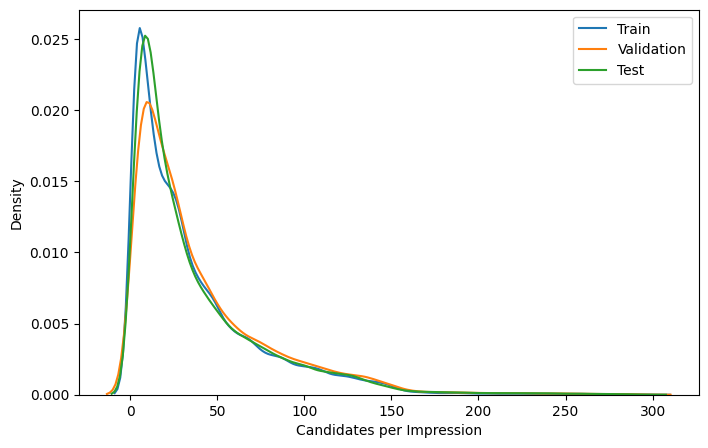

In [24]:
# Impression Slate Lengths
def slate_lengths(df):

    return (
        df["impressions"]
        .str.split()
        .apply(len)
    )

for name, subset in {
    "Train": train,
    "Validation": val,
    "Test": test
}.items():

    lengths = slate_lengths(subset)

    print(
        name,
        lengths.mean(),
        lengths.median()
    )


plt.figure(figsize=(8,5))

sns.kdeplot(
    slate_lengths(train),
    label="Train"
)

sns.kdeplot(
    slate_lengths(val),
    label="Validation"
)

sns.kdeplot(
    slate_lengths(test),
    label="Test"
)

plt.xlabel("Candidates per Impression")
plt.legend()
plt.show()

### User Activity Distribution

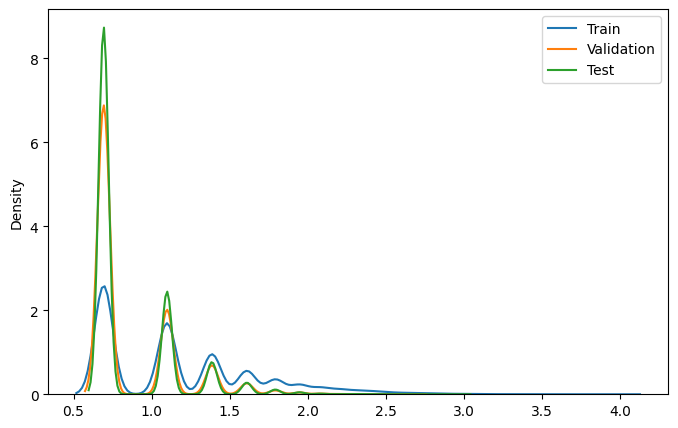

In [25]:
# User Activity Distribution

train_user_counts = (
    train.groupby("user_id")
         .size()
)

val_user_counts = (
    val.groupby("user_id")
       .size()
)

test_user_counts = (
    test.groupby("user_id")
        .size()
)

plt.figure(figsize=(8,5))

sns.kdeplot(
    np.log1p(train_user_counts),
    label="Train"
)

sns.kdeplot(
    np.log1p(val_user_counts),
    label="Validation"
)

sns.kdeplot(
    np.log1p(test_user_counts),
    label="Test"
)

plt.legend()
plt.show()

### News Category Distribution

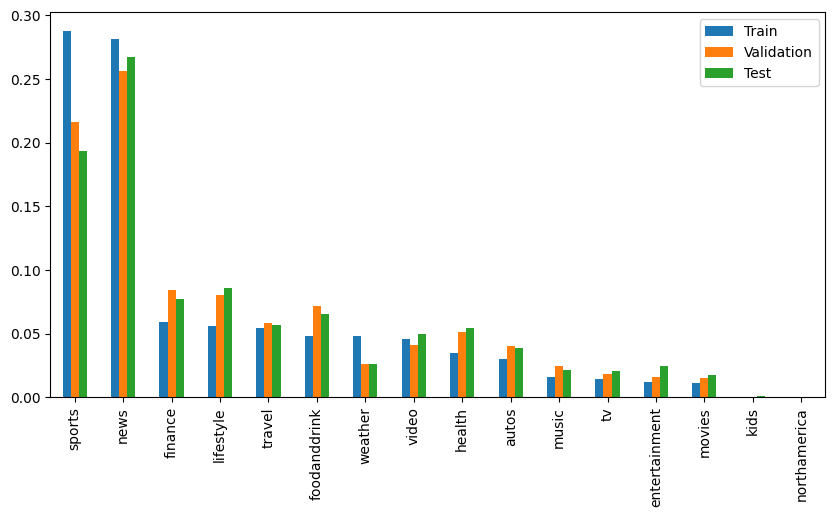

In [26]:
# News Category Distribution
news_lookup = dict(
    zip(news["news_id"], news["category"])
)

def category_dist(news_ids):

    categories = [
        news_lookup.get(news_id)
        for news_id in news_ids
        if news_id in news_lookup
    ]

    return (
        pd.Series(categories)
        .value_counts(normalize=True)
    )

train_cat = category_dist(train_news)
val_cat = category_dist(val_news)
test_cat = category_dist(test_news)

cat_df = pd.concat([
    train_cat.rename("Train"),
    val_cat.rename("Validation"),
    test_cat.rename("Test")
], axis=1)

cat_df.plot(
    kind="bar",
    figsize=(10,5)
)
plt.show()

In [27]:
train.head()

,impression_id,user_id,time,history,impressions,date
0,1,U13740,2019-11-11 09:05:58,N55189 N42782 N34694 N45794 N18445 N63302 N104...,N55689-1 N35729-0,2019-11-11
1,2,U91836,2019-11-12 18:11:30,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,N20678-0 N39317-0 N58114-0 N20495-0 N42977-0 N...,2019-11-12
3,4,U34670,2019-11-11 05:28:05,N45729 N2203 N871 N53880 N41375 N43142 N33013 ...,N35729-0 N33632-0 N49685-1 N27581-0,2019-11-11
4,5,U8125,2019-11-12 16:11:21,N10078 N56514 N14904 N33740,N39985-0 N36050-0 N16096-0 N8400-1 N22407-0 N6...,2019-11-12
5,6,U19739,2019-11-11 18:52:13,N39074 N14343 N32607 N32320 N22007 N442 N19001...,N21119-1 N53696-0 N33619-1 N25722-0 N2869-0,2019-11-11


### Hour-of-Day Distribution

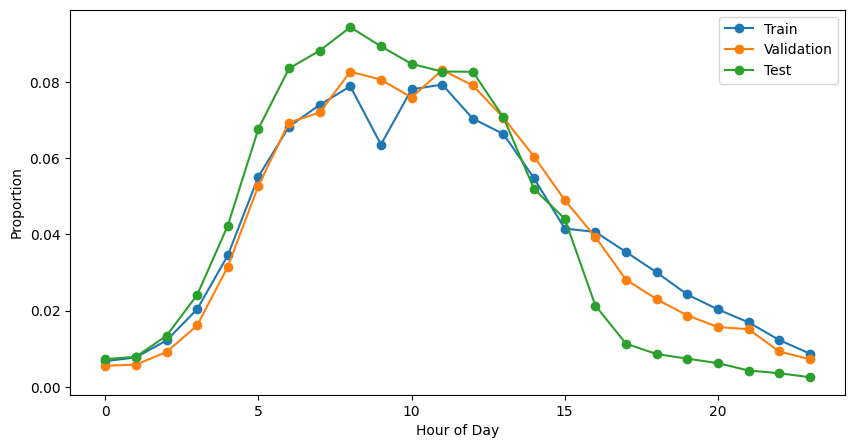

In [28]:
# Hour-of-Day Distribution

for df in [train,val,test]:
    df["hour"] = df["time"].dt.hour

plt.figure(figsize=(10,5))

for name,data in zip(
    ["Train","Validation","Test"],
    [train,val,test]
):

    dist = (
        data["hour"]
        .value_counts(normalize=True)
        .sort_index()
    )

    plt.plot(
        dist.index,
        dist.values,
        marker="o",
        label=name
    )

plt.xlabel("Hour of Day")
plt.ylabel("Proportion")
plt.legend()
plt.show()